# Data Preperation

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
from sklearn.preprocessing import MinMaxScaler

In [4]:
from sklearn.model_selection import train_test_split

In [5]:
df=pd.read_csv('/content/drive/MyDrive/synthetic_inventory_data.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/synthetic_inventory_data.csv'

In [6]:
df.head()

,date,product_id,product_category,sales,retrieval_frequency,warehouse_location,stock_level,restock_lead_time,storage_constraints,price
0,2023-01-01,1,Food,5,9,Aisle-8-Shelf-1,75,6,Fragile,200.30
1,2023-01-01,2,Clothing,15,3,Aisle-7-Shelf-1,138,5,Fragile,491.75
2,2023-01-01,3,Books,10,3,Aisle-4-Shelf-5,105,6,Fragile,30.39
3,2023-01-01,4,Food,43,8,Aisle-1-Shelf-1,183,7,Temperature-Sensitive,206.07
4,2023-01-01,5,Furniture,49,9,Aisle-1-Shelf-3,126,2,Temperature-Sensitive,13.17


In [7]:
df.shape

(18250, 10)

In [8]:
df.describe()

,product_id,sales,retrieval_frequency,stock_level,restock_lead_time,price
count,18250.000000,18250.000000,18250.000000,18250.000000,18250.000000,18250.000000
mean,25.500000,24.955507,5.481918,109.512384,4.016932,255.686261
std,14.431265,14.743527,2.872055,52.532071,2.010954,141.071773
min,1.000000,0.000000,1.000000,20.000000,1.000000,10.000000
25%,13.000000,12.000000,3.000000,65.000000,2.000000,133.710000
50%,25.500000,25.000000,5.000000,109.000000,4.000000,255.025000
75%,38.000000,38.000000,8.000000,156.000000,6.000000,377.440000
max,50.000000,50.000000,10.000000,200.000000,7.000000,499.980000


In [9]:
df['date']=pd.to_datetime(df['date'])

In [10]:
df=df.sort_values(by='date')

aggregate data by product and date

In [11]:
data=df.groupby(['date','product_id']).sum().reset_index()

prepare for timeseries modeling

In [12]:
pivot_data=data.pivot(index='date',columns='product_id',values='sales').fillna(0)
scaler=MinMaxScaler()
scaled_data=scaler.fit_transform(pivot_data)

In [13]:
data.head()

,date,product_id,product_category,sales,retrieval_frequency,warehouse_location,stock_level,restock_lead_time,storage_constraints,price
0,2023-01-01,1,Food,5,9,Aisle-8-Shelf-1,75,6,Fragile,200.30
1,2023-01-01,2,Clothing,15,3,Aisle-7-Shelf-1,138,5,Fragile,491.75
2,2023-01-01,3,Books,10,3,Aisle-4-Shelf-5,105,6,Fragile,30.39
3,2023-01-01,4,Food,43,8,Aisle-1-Shelf-1,183,7,Temperature-Sensitive,206.07
4,2023-01-01,5,Furniture,49,9,Aisle-1-Shelf-3,126,2,Temperature-Sensitive,13.17


prepare sequences for LSTM

In [14]:
def create_sequences(data,seq_length=30):
  sequences,targets=[],[]
  for i in range(len(data)-seq_length):
    sequences.append(data[i:i+seq_length])
    targets.append(data[i+seq_length])
  return np.array(sequences),np.array(targets)

In [15]:
seq_length=30

In [16]:
X,y=create_sequences(scaled_data,seq_length)

split data into training and testing sets

In [17]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

## LSTM Model For Demand Forecasting

In [18]:
import tensorflow as tf

In [19]:
from tensorflow.keras.models import Sequential

In [20]:
from tensorflow.keras.layers import LSTM,Dense,Dropout

Define LSTM models

In [21]:
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(seq_length, X_train.shape[2])),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(X_train.shape[2])
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


compile the model

In [22]:
model.compile(optimizer='adam',loss='mean_squared_error')

train the model

In [23]:
history=model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=20,batch_size=32)

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - loss: 0.3601 - val_loss: 0.2365
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - loss: 0.2375 - val_loss: 0.1590
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.1683 - val_loss: 0.1092
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 0.1315 - val_loss: 0.0907
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.1172 - val_loss: 0.0885
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.1121 - val_loss: 0.0882
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.1074 - val_loss: 0.0891
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.1053 - val_loss: 0.0882
Epoch 9/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.1034 - val_loss: 0.0877
Epoch 10/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.1021 - val_loss: 0.0883
Epoch 11/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.1002 - val_loss: 0.0884
Epoch 12/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0981 - val_loss: 0.0878


make predictions

In [24]:
predictions=model.predict(X_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 159ms/step


In [25]:
predictions=scaler.inverse_transform(predictions)

## Reinforcement Learning For Stock Placement

In [26]:
import gym

In [27]:
import numpy as np

In [ ]:
!pip install stable_baselines3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.5/184.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 98.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 85.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 77.9 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstallin

In [ ]:
from stable_baselines3 import PPO

Custom Warehouse Enviornment

In [ ]:
class WarehouseEnv(gym.Env):
  def __init__(self,num_items,num_shelves):
    super(WarehouseEnv,self).__init__()
    self.num_items=num_items
    self.num_shelves=num_shelves

    self.action_space=gym.spaces.Discrete(num_shelves)
    self.observation_space=gym.spaces.MultiDiscrete([num_shelves]*num_items)

    self.state=np.zeros(num_items,dtype=int)
    self.done=False

  def step(self,action):
    item_to_place=np.random.randint(0,self.num_items)
    self.state[item_to_place]=action

    reward=-np.abs(item_to_place - action)

    self.done=all(self.state!=0)
    return self.state,reward,self.done,{}

  def reset(self):
    self.state=np.zeros(self.num_items,dtype=int)
    self.done=False
    return self.state

create enviornment

In [ ]:
env=WarehouseEnv(num_items=10,num_shelves=5)

train RL agent using PPO

In [ ]:
!pip install 'shimmy>=2.0' # install shimmy to support OpenAI Gym environments

In [ ]:
model=PPO('MlpPolicy',env,verbose=1)

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.11/dist-packages/stable_baselines3/common/vec_env/patch_gym.py:49: UserWarning: You provided an OpenAI Gym environment. We strongly recommend transitioning to Gymnasium environments. Stable-Baselines3 is automatically wrapping your environments in a compatibility layer, which could potentially cause issues.
  warnings.warn(


In [ ]:
model.learn(total_timesteps=10000)

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 69.8     |
|    ep_rew_mean     | -230     |
| time/              |          |
|    fps             | 918      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 58.9        |
|    ep_rew_mean          | -191        |
| time/                   |             |
|    fps                  | 602         |
|    iterations           | 2           |
|    time_elapsed         | 6           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.008487361 |
|    clip_fraction        | 0.0806      |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.6        |
|    explained_variance   | 0.000557    |
|    learning_rate        | 0.

test the model

In [ ]:
obs=env.reset()
for _ in range(100):
    action, _states = model.predict(obs)
    obs, rewards, done, info = env.step(action)
    if done:
        break

In [ ]:
print("Optimized item placement",obs)

Optimized item placement [4 3 4 2 1 2 2 4 3 3]


In [ ]:
import matplotlib.pyplot as plt

plot forecast vs actual demand

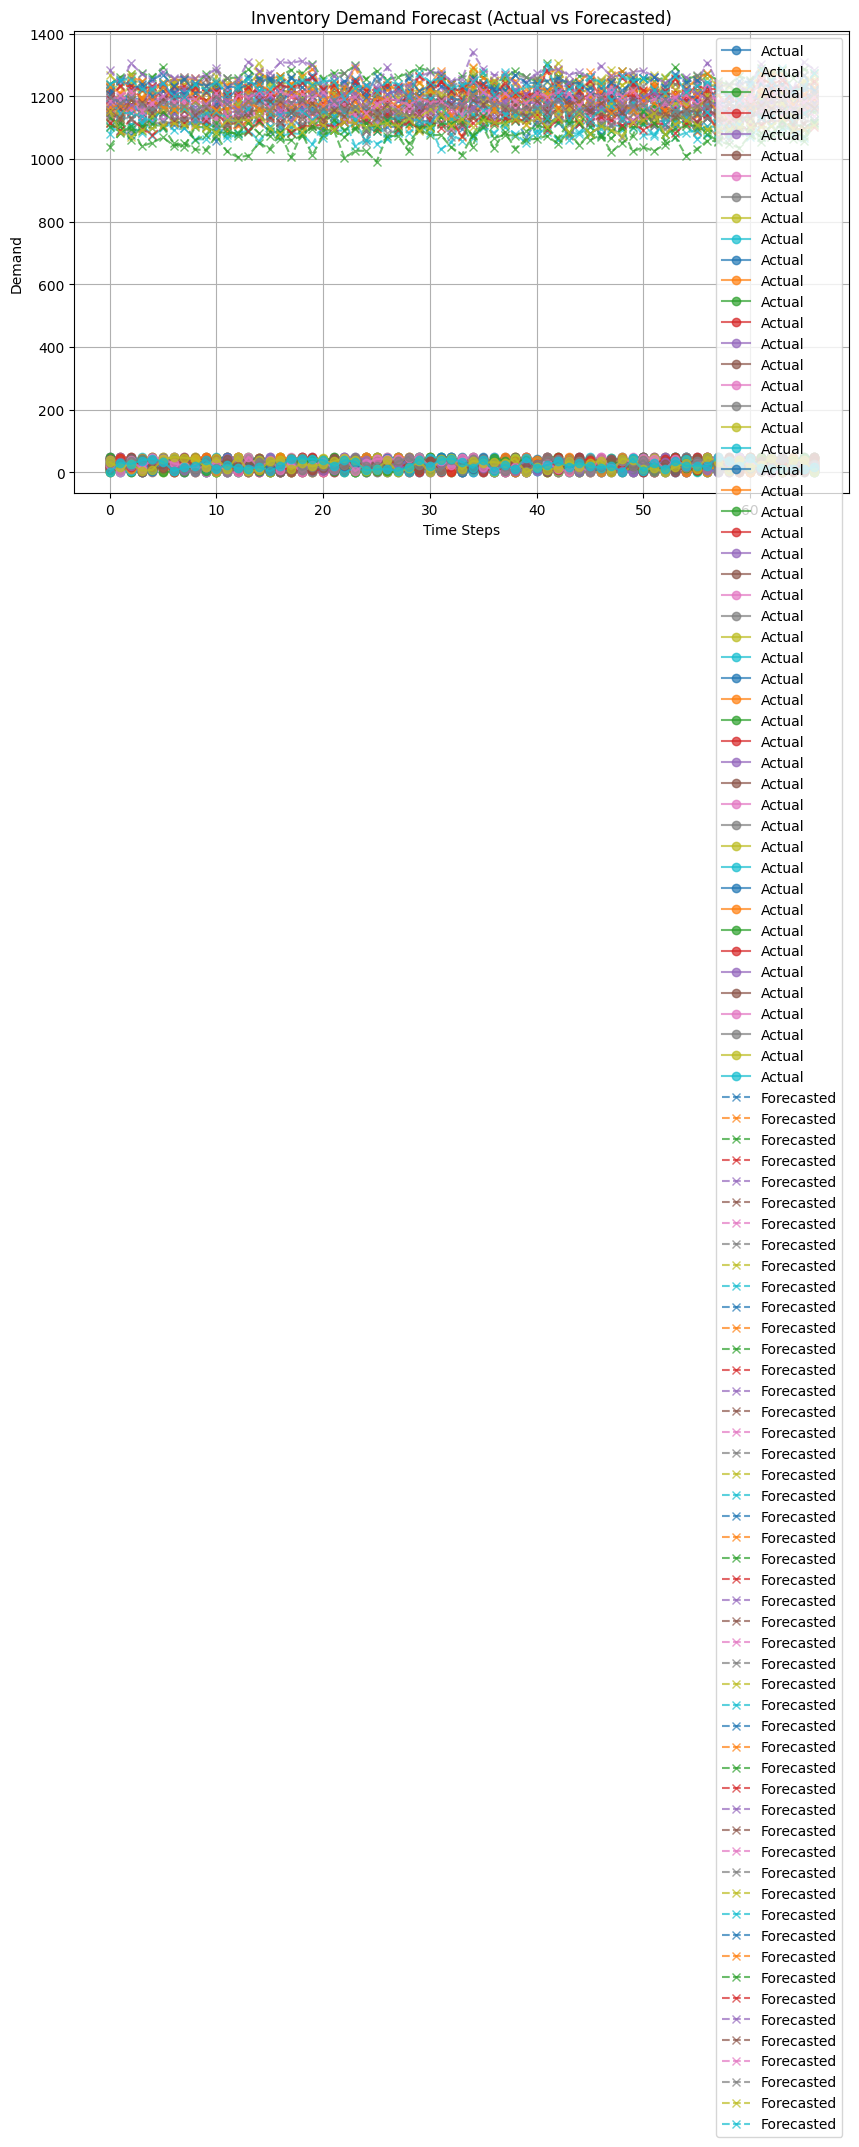

In [ ]:

y_test_rescaled = scaler.inverse_transform(y_test)
predictions_rescaled = scaler.inverse_transform(predictions)

plt.figure(figsize=(10, 6))
plt.plot(y_test_rescaled[:100], label='Actual', marker='o', linestyle='-', alpha=0.7)
plt.plot(predictions_rescaled[:100], label='Forecasted', marker='x', linestyle='--', alpha=0.7)
plt.xlabel("Time Steps")
plt.ylabel("Demand")
plt.title("Inventory Demand Forecast (Actual vs Forecasted)")
plt.legend()
plt.grid(True)
plt.show()


visualize RL placement

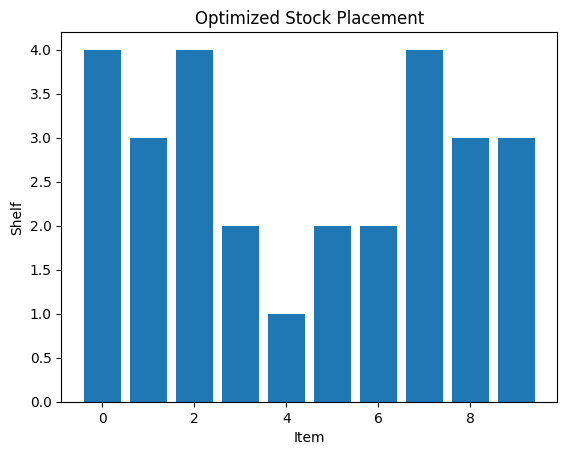

In [ ]:
placement = obs  # Final RL placement state
plt.bar(range(len(placement)), placement)
plt.xlabel("Item")
plt.ylabel("Shelf")
plt.title("Optimized Stock Placement")
plt.show()